# Hamiltonian Neural Networks: learning physics that conserves energy

## The problem

Suppose we want a neural network to learn how a physical system moves, using only measured data. The usual recipe is to train the network to predict the rate of change of the state (how fast position and momentum are changing), and then to simulate the system by repeatedly stepping that prediction forward in time.

This works for a few steps and then goes wrong. Each prediction has a small error, the errors accumulate as we integrate, and the simulated system slowly gains or loses energy that a real, frictionless system would keep exactly. A simulated pendulum may swing a little higher on every pass, or a planet may spiral away from its orbit.

## The idea

Classical mechanics offers a different way to describe motion. Instead of writing down the motion directly, we write down one scalar function, the **Hamiltonian** $H(q, p)$, which gives the total energy of the system for a position $q$ and a momentum $p$. The motion then follows from two equations:

$$\frac{dq}{dt} = \frac{\partial H}{\partial p}, \qquad \frac{dp}{dt} = -\frac{\partial H}{\partial q}$$

Along any path that obeys these equations the energy cannot change:

$$\frac{dH}{dt} = \frac{\partial H}{\partial q}\frac{dq}{dt} + \frac{\partial H}{\partial p}\frac{dp}{dt} = \frac{\partial H}{\partial q}\frac{\partial H}{\partial p} - \frac{\partial H}{\partial p}\frac{\partial H}{\partial q} = 0$$

A **Hamiltonian Neural Network (HNN)** uses this structure. The network does not output the motion. It outputs a single number, its estimate of $H$, and we obtain the motion by differentiating the network with automatic differentiation. Whatever function the network has learned, the motion it generates conserves that function exactly. Energy conservation is built into the architecture instead of being something the network has to learn.

## What this notebook does

For each physical system we train two models that have the same size, the same data and the same training procedure:

| Model | What the network outputs | Conservation |
|---|---|---|
| **Baseline** | the time derivatives $(dq/dt,\ dp/dt)$ directly | none, so it must be learned from data |
| **HNN** | one scalar $H$; the derivatives come from its gradient | exact, by construction |

We then compare them on three questions:

1. **Single-step accuracy.** How well does each network predict the derivatives on training and test points (train and test loss)?
2. **Long-term energy.** If we simulate from a starting point, does the energy stay where it should (energy MSE)?
3. **Path accuracy.** Does the simulated path stay close to the true path (coordinate MSE)?

The first question is about fitting data. The other two are about whether a model is usable as a simulator, which is where we expect the two approaches to differ.

## Contents

| Section | System | What it tests |
|---|---|---|
| **0** | | Shared code: models, data, training, metrics and plots |
| **1** | Ideal mass-spring | A simple linear system with exact energy conservation |
| **2** | Ideal pendulum | A nonlinear system, still with exact conservation |
| **3** | Damped spring and pendulum | What happens when energy is *not* conserved |
| **4** | Two-body gravitational orbit | A larger, 8-dimensional system |


## 0. Setup and helpers

This section defines everything the experiments share. Nothing is trained here, and the cells only define functions.

**Systems are plain dictionaries.** Each experiment describes its physical system with one dictionary, and every helper takes that dictionary as input. A new experiment therefore only has to build a dictionary and call the same functions.

| Key | Meaning |
|---|---|
| `label`, `title` | names used in plot titles |
| `H(q, p)` | the true energy function |
| `f(t, s)` | the true dynamics, returning $(dq/dt,\ dp/dt)$ |
| `radius` | range of distances from the origin of the (q, p) plane used for training start points |
| `n_points` | number of samples per training trajectory |
| `start` | the start point used for the figures and for the coordinate error |
| `time_scale` | a correction factor for integration time, explained under *Integration and metrics* |

**Conventions.** A state is a vector $(q_1, \dots, q_n, p_1, \dots, p_n)$ with all positions first and all momenta second. A *field* is a function that maps a state to its time derivative. The baseline field is the network itself. The HNN field is built from the network's gradient.

In [1]:
import numpy as np, torch, torch.nn as nn
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ---- saving helpers: everything is written to the "results" folder ----
import os, re, csv, json, shutil
RESULTS_DIR = 'results'
os.makedirs(RESULTS_DIR, exist_ok=True)
ALL_ROWS = []                                              # every metrics row, collected for all_metrics.csv

def slug(s):                                               # "Damped mass-spring (γ=0.1)" -> "Damped_mass_spring_0_1"
    return re.sub(r'[^a-zA-Z0-9]+', '_', s).strip('_')

def save_fig(name):
    path = os.path.join(RESULTS_DIR, f'{slug(name)}.png')
    plt.savefig(path, dpi=200, bbox_inches='tight')

def save_rows(rows, name):                                 # list of dicts -> results/<name>.csv
    fields = list(dict.fromkeys(k for r in rows for k in r))
    with open(os.path.join(RESULTS_DIR, f'{name}.csv'), 'w', newline='') as f:
        w = csv.DictWriter(f, fieldnames=fields, restval=''); w.writeheader(); w.writerows(rows)

def save_nets(nets, prefix):                               # trained weights -> results/<prefix>_<model>.pt
    for kind, net in nets.items():
        torch.save(net.state_dict(), os.path.join(RESULTS_DIR, f'{prefix}_{kind}.pt'))


**Models.**

Both models are the same small multilayer perceptron (MLP): two hidden layers of 200 units with $\tanh$ activations. They differ only in what the final layer means.

- **Baseline.** The output has the same size as the state, and it is read as the predicted time derivative $(dq/dt,\ dp/dt)$.
- **HNN.** The output is a single number, interpreted as the energy $H(q, p)$. `hnn_field` turns it into a time derivative in four steps:
  1. Make a copy of the input that tracks gradients.
  2. Sum the network's output over the batch. Each sample's energy depends only on its own input, so the gradient of the sum with respect to the inputs gives each sample's own gradient.
  3. Use automatic differentiation to get $(\partial H/\partial q,\ \partial H/\partial p)$. The option `create_graph=True` keeps this gradient inside the computation graph, so training can later adjust the network's weights *through* the gradient.
  4. Rearrange to $(\partial H/\partial p,\ -\partial H/\partial q)$, which is Hamilton's equations. With $n$ position–momentum pairs, the first half of the state is positions and the second half is momenta, so the same function works for one pair or for four.

**Design choices.**

- $\tanh$ is smooth. The HNN needs the network's *derivative*, and then trains on that derivative, so the network must be differentiable twice. A ReLU network has a piecewise-constant gradient, which gives a poor learning signal.
- The final layer has no bias. A constant added to $H$ has no effect on the gradient, so the bias would be wasted for the HNN, and we keep the baseline identical.
- Weights start orthogonal, a standard choice that keeps signal magnitudes stable across layers.

In [2]:
def make_mlp(in_dim, out_dim, hidden=200):
    net = nn.Sequential(nn.Linear(in_dim, hidden), nn.Tanh(),
                        nn.Linear(hidden, hidden), nn.Tanh(),
                        nn.Linear(hidden, out_dim, bias=False))
    for layer in net:
        if isinstance(layer, nn.Linear): nn.init.orthogonal_(layer.weight)
    return net

def baseline_field(net, x):
    return net(x)                                          # directly predicts the derivatives

def hnn_field(net, x):
    x = x.clone().requires_grad_(True)                     # we need dH/dx
    H = net(x).sum()                                       # one energy per point, summed
    dH = torch.autograd.grad(H, x, create_graph=True)[0]   # (dH/dq, dH/dp)
    n = x.shape[1] // 2                                    # state is (q_1..q_n, p_1..p_n)
    return torch.cat([dH[:, n:], -dH[:, :n]], dim=1)       # (dH/dp, -dH/dq)

FIELDS = {'baseline': baseline_field, 'hnn': hnn_field}

**Data.**

The training data is simulated from the true equations of motion, with measurement noise added in a controlled way.

1. **Start points.** Each trajectory starts at a random direction in the (q, p) plane and a random distance from the origin, within the system's `radius` range. This produces a spread of energies.
2. **Simulation.** We integrate the true equations for 3 time units with a high-accuracy solver (relative tolerance $10^{-10}$) and record 30 or 45 points per trajectory, depending on the system.
3. **Targets.** The label for each recorded point is the *exact* time derivative from the true equations, evaluated at the clean point.
4. **Noise.** Gaussian noise with standard deviation 0.1 is added to the **inputs only**. The network sees noisy states and has to predict the clean derivative. This mimics noisy sensors with correct labels, and it tests robustness. The noise is also why a loss of exactly zero is impossible: some of the input is irreducible noise.
5. **Split.** 50 trajectories are generated. The first half is the training set and the second half is the test set, so test points come from trajectories the network has never seen.

Each point is treated as an independent sample of "state in, derivative out". The network does not see the time order of the points.

In [3]:
def make_trajectory(system, noise_std=0.1):
    y0 = np.random.rand(2)*2 - 1
    y0 = y0 / np.linalg.norm(y0) * np.random.uniform(*system['radius'])   # random start at a random radius
    t = np.linspace(0, 3, system['n_points'])
    states = solve_ivp(system['f'], (0, 3), y0, t_eval=t, rtol=1e-10).y   # clean (q, p), shape (2, T)
    targets = np.array(system['f'](0, states))                            # exact (dq/dt, dp/dt)
    inputs = states + noise_std * np.random.randn(*states.shape)          # noise on inputs only
    return inputs.T, targets.T

def make_dataset(system, seed=0, n_traj=50, noise_std=0.1):
    np.random.seed(seed)
    xs, dxs = zip(*[make_trajectory(system, noise_std) for _ in range(n_traj)])
    x, dx = np.concatenate(xs), np.concatenate(dxs)
    half = len(x) // 2
    T = lambda a: torch.tensor(a, dtype=torch.float32)
    return dict(x_train=T(x[:half]), dx_train=T(dx[:half]),
                x_test=T(x[half:]),  dx_test=T(dx[half:]))

**Training and loss.**

Both models are trained with the same supervised regression loop. The loss is the mean squared error(MSE) between the predicted and true derivatives. We use the Adam optimizer (learning rate $10^{-3}$, weight decay $10^{-4}$), the full training set in each step, and 2000 steps. Only the function `FIELDS[kind]` differs between the two models.

`evaluate` reports the mean squared error on a set of points and its standard error, which is the standard deviation of the squared errors divided by the square root of the number of points. A difference between two models is only meaningful if it is larger than these error bars.

**What the loss does not tell us.** The loss measures how well a model predicts the derivative at *one* point. A model can have a small loss and still be a bad simulator, because a simulator applies the prediction thousands of times, and small errors add up. The metrics below measure that.

In [4]:
def train(kind, data, steps=2000, lr=1e-3, verbose=True):
    torch.manual_seed(0)
    in_dim = data['x_train'].shape[1]
    net = make_mlp(in_dim, 1 if kind == 'hnn' else in_dim)
    field = FIELDS[kind]
    opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=1e-4)
    for step in range(steps + 1):
        loss = ((field(net, data['x_train']) - data['dx_train'])**2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
        if verbose and step % 400 == 0: print(kind, step, round(loss.item(), 4))
    return net

def evaluate(kind, net, x, dx):                            # mean and standard error of the squared error
    sq = (FIELDS[kind](net, x).detach() - dx)**2
    return sq.mean().item(), (sq.std() / np.sqrt(len(sq))).item()

**Integration and metrics.**

To use a learned model as a simulator, we integrate its vector field forward in time from a starting state with an adaptive Runge–Kutta solver (relative tolerance $10^{-9}$). We then compare the result with the true solution from the same start.

- **Energy MSE** (`energy_eval`) measures energy conservation. For 15 random start points we simulate 20 time units (100 points each) and compare the *true* energy at the model's path with the true energy at the true path. The result is the mean squared difference. A model that drifts to a higher or lower energy scores badly. The 15 start points have coordinates with magnitude between 0.2 and 1.0, and part of that range lies outside the radii used in training, so the metric also checks how well a model extrapolates. All models see the same start points. The error bar comes from splitting the 15 starts into 5 groups of 3 and taking the standard deviation of the group means divided by $\sqrt{5}$.
- **Coordinate MSE** (`coord_mse`) measures how far the simulated path is from the true path. It starts both from the system's `start` point, integrates for 20 time units, and averages the squared difference in $q$ and $p$ over time. It is stricter than the energy metric: a model can keep the right energy and still be in the wrong place along its orbit, which counts as an error here. It uses a single start point, so it is noisier.
- **`time_scale`.** Because the inputs are noisy and the labels are clean, a network learns a slightly *shrunk* version of the true derivative. A learned spring then oscillates a little slower than the real one, even if its energy is right, and over many oscillations it falls out of phase with the true path. For the spring we integrate learned models for `time_scale` times as long as the true path and compare the two index by index, which compensates for this slowdown. The value (1.09 for the spring, 1.0 for the others) was chosen empirically so that the coordinate error reflects real modelling error and not just the phase lag.

In [5]:
def integrate(kind, net, x0, t_end=20, n=100, time_scale=1.0):
    def rhs(t, s):
        x = torch.tensor(s, dtype=torch.float32).view(1, -1)
        return FIELDS[kind](net, x).detach().numpy().reshape(-1)
    t_eval = np.linspace(0, t_end, n) * time_scale
    return solve_ivp(rhs, (0, t_end * time_scale), x0, t_eval=t_eval, rtol=1e-9).y.T

def true_path(system, x0, t_end=20, n=100):
    return solve_ivp(system['f'], (0, t_end), x0,
                     t_eval=np.linspace(0, t_end, n), rtol=1e-9).y.T

def energy_eval(system, kind, net, n_starts=15):
    rng, errs = np.random.RandomState(1), []
    for _ in range(n_starts):
        x0 = rng.rand(2)*1.6 - 0.8
        x0 += 0.2 * np.sign(x0)
        true = true_path(system, x0)
        pred = integrate(kind, net, x0, time_scale=system['time_scale'])
        errs.append(np.mean((system['H'](*true.T) - system['H'](*pred.T))**2))
    groups = np.array(errs).reshape(5, 3).mean(1)
    return np.mean(errs), groups.std() / np.sqrt(5)

def coord_mse(system, kind, net):
    x0 = np.array(system['start'])
    true = true_path(system, x0)
    pred = integrate(kind, net, x0, time_scale=system['time_scale'])
    return ((pred - true)**2).mean()

**Reporting and plots.**

`report` prints one table per system, with a row for each model:

- `train` and `test`: mean squared error of the derivative, with standard error, scaled by $10^3$.
- `energy`: the energy MSE described above, also scaled by $10^3$.
- `coord MSE`: the coordinate error, unscaled.

`plot_fig2` draws four panels for one start point and a simulation of 20 time units, each showing the ground truth in black, the baseline in red and the HNN in blue:

1. **Predictions.** The path in the (q, p) plane. A conserving model traces a closed loop, and a model that gains or loses energy spirals.
2. **MSE between coordinates.** The error of each simulated path against the true path over time.
3. **HNN-conserved quantity.** The network's own energy $H_\theta$ evaluated along each path. It is only trained through its gradient, so it can differ from the true energy by an additive constant. Compare its *shape*, not its absolute value. A flat line for the HNN is the guarantee of the method.
4. **Total energy.** The *true* energy function evaluated along each path. This is the physically meaningful check.

`run_experiment` runs the whole pipeline for one system: generate the data, train both models, print the table and draw the figure.
**Saving results.** Everything is saved to a `results/` folder (created in Section 0):

| File | Contents |
|---|---|
| `<system>.png` | the four-panel figure for each system, plus `gamma_sweep.png`, `two_body_energy_and_trajectories.png` and `two_body_energy_grid.png` |
| `<system>_metrics.csv` | train, test, energy and coordinate MSE with standard errors, per model (raw values, not scaled by $10^3$ or $10^6$) |
| `gamma_sweep.json` / `.csv` | coordinate MSE against damping strength |
| `<system>_<model>.pt` | trained network weights (`net.load_state_dict(torch.load(path))`) |
| `two_body_energy_runs.npz` | the energy curves behind the two-body plots |
| `all_metrics.csv`, `results.zip` | written by the last cell, which combines all metrics and zips the folder |


In [6]:
def report(system, result):
    d = result['data']; print(system['title']); rows = []
    for kind, net in result['nets'].items():
        tr = evaluate(kind, net, d['x_train'], d['dx_train'])
        te = evaluate(kind, net, d['x_test'],  d['dx_test'])
        en = energy_eval(system, kind, net)
        cm = coord_mse(system, kind, net)
        print(f"  {kind:8s} train {tr[0]*1e3:6.1f}±{tr[1]*1e3:.1f}  test {te[0]*1e3:6.1f}±{te[1]*1e3:.1f}  "
              f"energy {en[0]*1e3:8.2f}±{en[1]*1e3:.2f}  coord MSE {cm:.3f}")
        rows.append(dict(system=system['title'], model=kind,          # raw values, NOT multiplied by 1e3
                         train_mse=tr[0], train_se=tr[1], test_mse=te[0], test_se=te[1],
                         energy_mse=en[0], energy_se=en[1], coord_mse=cm))
    save_rows(rows, f"{slug(system['title'])}_metrics"); ALL_ROWS.extend(rows)

def plot_fig2(system, nets, t_end=20, n=2000):
    x0 = np.array(system['start']); t = np.linspace(0, t_end, n); ts = system['time_scale']
    true = true_path(system, x0, t_end, n)
    paths = {'Ground truth': true,
             'Baseline NN': integrate('baseline', nets['baseline'], x0, t_end, n, ts),
             'Hamiltonian NN': integrate('hnn', nets['hnn'], x0, t_end, n, ts)}
    color = {'Ground truth': 'k', 'Baseline NN': 'r', 'Hamiltonian NN': 'b'}
    learned_H = lambda p: nets['hnn'](torch.tensor(p, dtype=torch.float32)).detach().numpy().squeeze()
    fig, ax = plt.subplots(1, 4, figsize=(15, 3.3))
    fig.suptitle(system['title'], fontsize=14)
    for label, p in paths.items():
        c = color[label]
        ax[0].plot(p[:, 0], p[:, 1], c, label=label)
        if label != 'Ground truth': ax[1].plot(t, ((p - true)**2).mean(1), c, label=label)
        ax[2].plot(t, learned_H(p), c, label=label)
        ax[3].plot(t, system['H'](p[:, 0], p[:, 1]), c, label=label)
    for a, title in zip(ax, ['Predictions', 'MSE between coordinates',
                             'HNN-conserved quantity', 'Total energy']):
        a.set_title(title)
    ax[0].legend(fontsize=7); plt.tight_layout(rect=[0, 0, 1, 0.94])
    save_fig(system['title']); plt.show()

def run_experiment(system):
    data = make_dataset(system)
    nets = {kind: train(kind, data) for kind in FIELDS}
    result = dict(data=data, nets=nets)
    report(system, result)
    plot_fig2(system, nets)
    save_nets(nets, slug(system['title']))
    return result

## 1. Ideal mass-spring

A mass $m$ on a spring of stiffness $k$, with no friction. The Hamiltonian is the sum of kinetic and potential energy:

$$H = \frac{p^2}{2m} + \frac{1}{2}k\,q^2 \qquad\Longrightarrow\qquad \frac{dq}{dt} = \frac{p}{m}, \qquad \frac{dp}{dt} = -k\,q$$

We use $m = 0.5$ and $k = 2$, so $H = p^2 + q^2$. Constant-energy paths in the (q, p) plane are circles, and the system oscillates with angular frequency $\sqrt{k/m} = 2$.

**Why start here.** It is the simplest nontrivial system: its dynamics are linear and its energy surface is a bowl. If an HNN cannot conserve energy here, it will not anywhere else.

**Setup.**
- Training start points have radius between 0.1 and 1.0, with 30 points per trajectory.
- The figures start at $(q, p) = (1, 0)$, which has energy 1, and run for 20 time units, roughly six full oscillations.
- `make_spring` takes the constants as arguments and builds the energy and dynamics functions around them, so their values are fixed inside the system and later code cannot change them by accident.
- `time_scale = 1.09` compensates for the noise-induced slowdown described above.

baseline 0 0.8616
baseline 400 0.0377
baseline 800 0.0398
baseline 1200 0.0373
baseline 1600 0.0372
baseline 2000 0.0416
hnn 0 0.7998
hnn 400 0.0371
hnn 800 0.037
hnn 1200 0.037
hnn 1600 0.037
hnn 2000 0.0369
Ideal mass-spring
  baseline train   40.2±2.1  test   39.4±2.0  energy    41.44±10.23  coord MSE 0.371
  hnn      train   36.9±1.9  test   35.9±1.8  energy     0.30±0.12  coord MSE 0.060


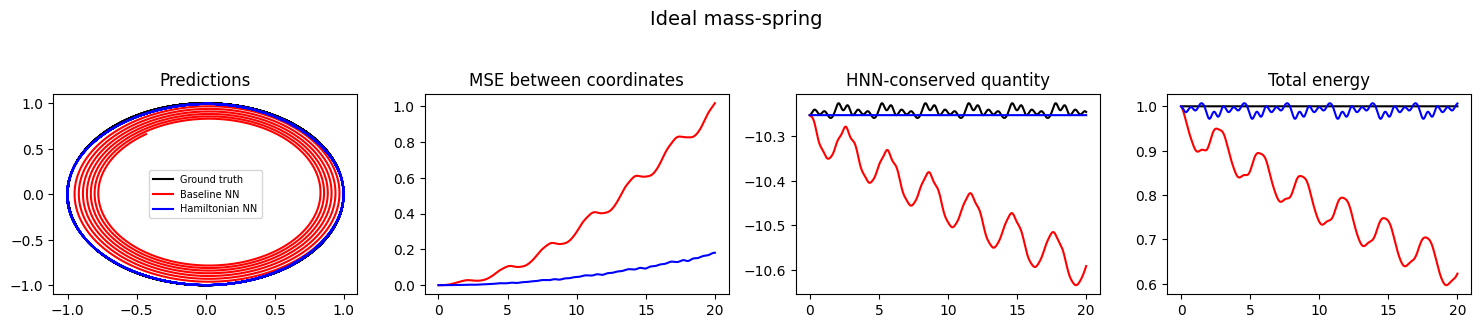

In [7]:
def make_spring(m, k, time_scale=1.09):
    return dict(label='mass-spring', title='Ideal mass-spring',
                H=lambda q, p: p**2/(2*m) + 0.5*k*q**2,
                f=lambda t, s: [s[1]/m, -k*s[0]],                  # (dH/dp, -dH/dq)
                radius=(0.1, 1.0), n_points=30, start=(1.0, 0.0),
                time_scale=time_scale)                              # compensates the noise-induced slowdown

spring = make_spring(m=0.5, k=2.0)
spring_result = run_experiment(spring)

## 2. Ideal pendulum

A point mass $m$ on a rigid rod of length $l$ in gravity $g$, with no friction. The angle is $q$ and $p$ is the angular momentum:

$$H = \frac{p^2}{2ml^2} + m g l\,(1 - \cos q) \qquad\Longrightarrow\qquad \frac{dq}{dt} = \frac{p}{ml^2}, \qquad \frac{dp}{dt} = -m g l \sin q$$

We use $m = 0.5$, $l = 1$ and $g = 9.8$.

**Why it is harder than the spring.** The $\sin q$ term makes the system nonlinear. The oscillation period depends on the amplitude, and constant-energy paths are rounded diamond shapes instead of circles. A network cannot get away with learning something close to a linear map.

**Setup.**
- Training start points have radius between 1.3 and 2.3, which covers swings of up to roughly 130°. This keeps every trajectory a back-and-forth swing (energy below $2mgl = 9.8$, the value at which the pendulum would tip over the top).
- Each trajectory has 45 points.
- The figures start at rest at $q = 2.1$ rad, with energy about 7.4.
- `time_scale = 1.0`: no correction was needed.

baseline 0 12.5425
baseline 400 0.0807
baseline 800 0.0635
baseline 1200 0.0623
baseline 1600 0.062
baseline 2000 0.0618
hnn 0 12.0472
hnn 400 0.0645
hnn 800 0.0619
hnn 1200 0.0612
hnn 1600 0.061
hnn 2000 0.061
Ideal pendulum
  baseline train   61.8±4.1  test   61.7±4.5  energy     2.45±0.41  coord MSE 0.637
  hnn      train   61.0±4.1  test   61.8±4.6  energy     1.42±0.13  coord MSE 0.182


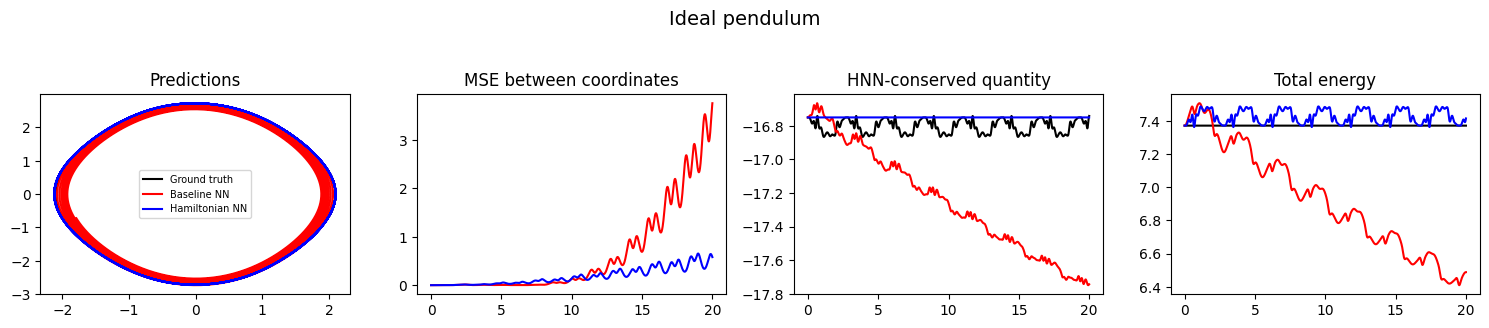

In [8]:
def make_pendulum(m, l, g, time_scale=1.0):
    return dict(label='pendulum', title='Ideal pendulum',
                H=lambda q, p: p**2/(2*m*l**2) + m*g*l*(1 - np.cos(q)),
                f=lambda t, s: [s[1]/(m*l**2), -m*g*l*np.sin(s[0])],
                radius=(1.3, 2.3), n_points=45, start=(2.1, 0.0),
                time_scale=time_scale)

pend = make_pendulum(m=0.5, l=1.0, g=9.8)
pend_result = run_experiment(pend)

## 3. Damped systems (friction)

**Question.** What happens when the system *loses* energy?

**Setup.** We add friction to the true dynamics by subtracting a term $\gamma p$ from $dp/dt$:

$$\frac{dq}{dt} = \frac{\partial H}{\partial p}, \qquad \frac{dp}{dt} = -\frac{\partial H}{\partial q} - \gamma\, p$$

Energy is now dissipated at a rate $dH/dt = -\gamma\, p\,\dot q \le 0$, so it decays and there is no conserved quantity. The parameter $\gamma$ sets the strength of the friction. For the spring, the energy falls roughly as $e^{-\gamma t}$, so at $\gamma = 0.1$ it drops to about 14% of its starting value over 20 time units.

**Why this matters.** An HNN can only move along contours of a single function $H$, so it has no way to represent a system whose energy changes. The baseline predicts the derivatives directly and has no such restriction. We therefore expect a **reversal**: the HNN's built-in structure is an advantage for frictionless systems and a limitation for dissipative ones. This experiment tests that prediction and shows where the two approaches cross over.

**Implementation.** `damped_system` takes any system and returns its damped version, with a new title and the friction term added to the dynamics. The energy function $H$ is kept as the *undamped* energy, so the energy panel shows how much energy the true system has lost.


In [9]:
def damped_system(base, gamma, time_scale=None):
    f = base['f']
    def f_damped(t, s):
        dq, dp = f(t, s)
        return [dq, dp - gamma * s[1]]                         # friction: extra -gamma*p in dp/dt
    return {**base, 'f': f_damped,
            'title': f"Damped {base['label']} (γ={gamma})",
            'time_scale': base['time_scale'] if time_scale is None else time_scale}

### 3a. One damping level (γ = 0.1)

We run the same pipeline as before (data, training, table and four-panel figure) on the damped spring and the damped pendulum at $\gamma = 0.1$.


baseline 0 0.7483
baseline 400 0.0375
baseline 800 0.0374
baseline 1200 0.0373
baseline 1600 0.0372
baseline 2000 0.0371
hnn 0 0.6917
hnn 400 0.0377
hnn 800 0.0376
hnn 1200 0.0376
hnn 1600 0.0375
hnn 2000 0.0375
Damped mass-spring (γ=0.1)
  baseline train   37.1±1.9  test   36.5±1.9  energy     8.23±2.04  coord MSE 0.102
  hnn      train   37.5±2.0  test   36.4±1.9  energy   425.41±106.74  coord MSE 0.105


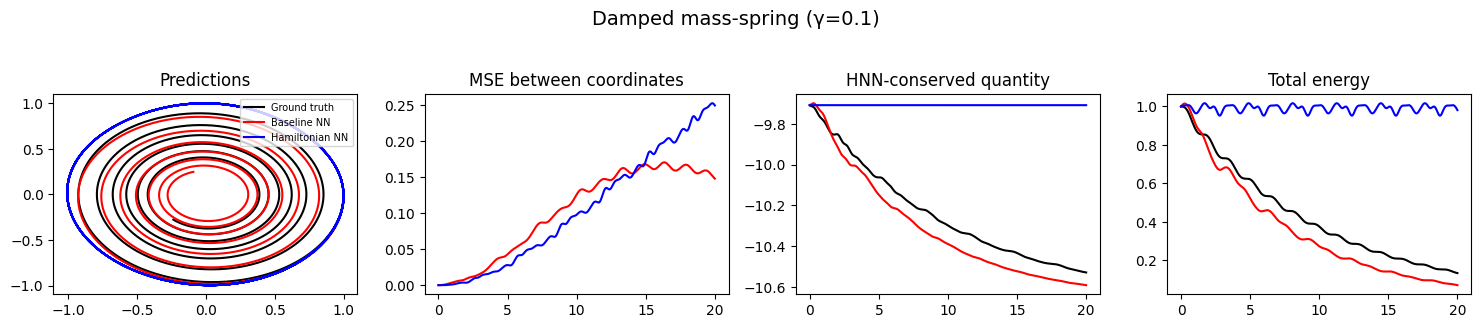

baseline 0 11.5947
baseline 400 0.0809
baseline 800 0.0688
baseline 1200 0.0672
baseline 1600 0.0667
baseline 2000 0.0665
hnn 0 11.1531
hnn 400 0.0729
hnn 800 0.0706
hnn 1200 0.0701
hnn 1600 0.0699
hnn 2000 0.0697
Damped pendulum (γ=0.1)
  baseline train   66.5±4.4  test   66.0±4.7  energy     1.85±0.17  coord MSE 0.066
  hnn      train   69.7±4.4  test   68.1±4.7  energy  1114.32±239.16  coord MSE 3.427


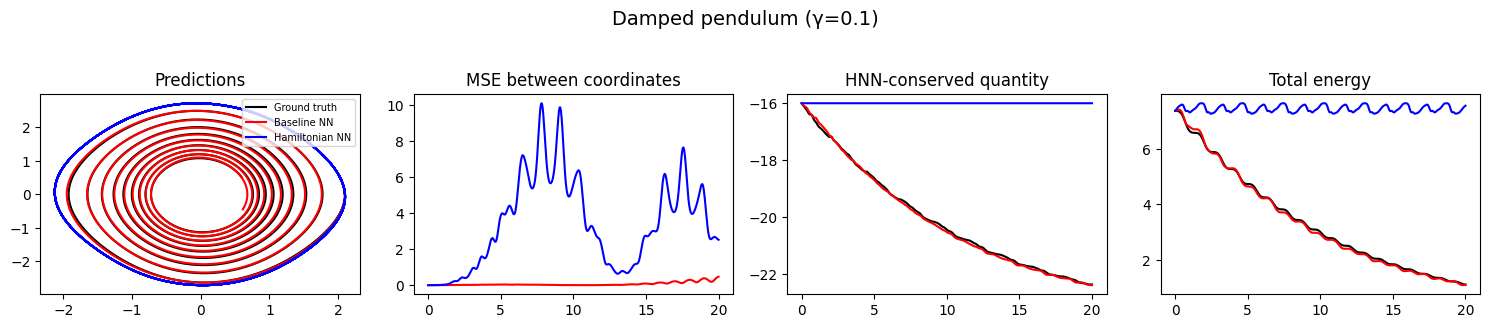

In [10]:
GAMMA = 0.1
damped_results = {}
for base in [spring, pend]:
    system = damped_system(base, GAMMA)
    damped_results[system['title']] = run_experiment(system)

### 3b. Sweep over damping strength

We repeat the experiment for $\gamma \in \{0, 0.05, 0.1, 0.2, 0.4\}$ and plot the coordinate MSE of each model against $\gamma$ on a logarithmic axis. At $\gamma = 0$ the system is the frictionless one from Sections 1 and 2.

**What to look for.** The HNN should win at $\gamma = 0$, the baseline should win once the friction is large enough, and the curves should cross in between. The crossover point depends on the system.


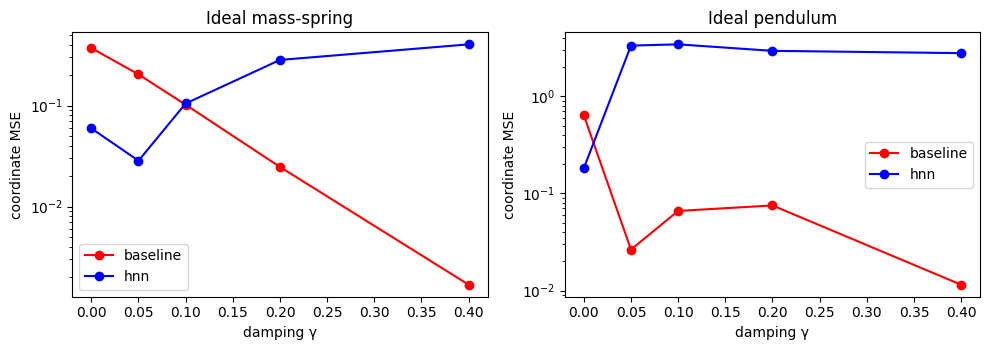

In [11]:
def gamma_sweep(bases, gammas):
    sweep = {}
    for base in bases:
        sweep[base['title']] = {kind: [] for kind in FIELDS}
        for gamma in gammas:
            system = damped_system(base, gamma)
            data = make_dataset(system)
            for kind in FIELDS:
                net = train(kind, data, verbose=False)
                sweep[base['title']][kind].append(coord_mse(system, kind, net))
    return sweep

def plot_gamma_sweep(sweep, gammas):
    fig, ax = plt.subplots(1, len(sweep), figsize=(5*len(sweep), 3.6))
    for a, (title, curves) in zip(np.atleast_1d(ax), sweep.items()):
        for kind, c in [('baseline', 'r'), ('hnn', 'b')]:
            a.plot(gammas, curves[kind], color=c, marker='o', label=kind)
        a.set_yscale('log'); a.set_xlabel('damping γ'); a.set_ylabel('coordinate MSE')
        a.set_title(title); a.legend()
    plt.tight_layout(); save_fig('gamma_sweep'); plt.show()

gammas = [0.0, 0.05, 0.1, 0.2, 0.4]
sweep = gamma_sweep([spring, pend], gammas)
plot_gamma_sweep(sweep, gammas)

# save the sweep numbers (JSON for reloading, CSV for spreadsheets)
json.dump(dict(gammas=gammas, sweep=sweep), open(os.path.join(RESULTS_DIR, 'gamma_sweep.json'), 'w'), indent=2)
sweep_rows = [dict(system=title, gamma=g, model=kind, coord_mse=v)
              for title, curves in sweep.items() for kind, vals in curves.items() for g, v in zip(gammas, vals)]
save_rows(sweep_rows, 'gamma_sweep')

## 4. Two-body system

Two bodies of equal mass attract each other by gravity and orbit their common centre. We set $m_1 = m_2 = g = 1$, and the energy is the kinetic energy of both bodies plus the gravitational potential energy:

$$H = \frac{|\mathbf{p}_1|^2}{2} + \frac{|\mathbf{p}_2|^2}{2} - \frac{1}{|\mathbf{q}_1 - \mathbf{q}_2|}$$

**Why this system.** It is a much bigger test than the earlier ones. The state has **8 numbers**, with the $x$ and $y$ position and momentum of each body, and the force between the bodies is strongly nonlinear.

**State layout.** The state is $(q_{x1}, q_{x2}, q_{y1}, q_{y2},\ p_{x1}, p_{x2}, p_{y1}, p_{y2})$. The first four numbers are positions and the last four are momenta, which is exactly the layout that `hnn_field` expects. The helpers from Section 0 therefore work without changes. The network has 8 inputs, the HNN has 1 output and the baseline has 8.

**Data.** Orbits start near circular:
- Body 1 starts at a random position with each coordinate in $[0.5, 1.5]$, and body 2 is placed at the mirror point through the origin. This keeps the centre of mass at rest at the origin and the total momentum at zero.
- Each body is given the speed that would produce a circular orbit, $1/(2\sqrt{r})$ for body 1 at distance $r$ from the origin, directed perpendicular to its position.
- That speed is then multiplied by $1 + 0.05\,\xi$, with $\xi$ drawn from a standard normal distribution. This makes the orbits slightly elliptical, so they differ from one another.
- We simulate 1000 orbits of 50 points over 20 time units (50,000 samples) and keep the first 20% as the test set. **No noise is added to the inputs** in this experiment, and the labels are the exact derivatives.

**Training.** The problem is bigger, so training differs from the earlier sections: 10,000 steps instead of 2000, random minibatches of 200 instead of the full training set, and no weight decay.

**Metric.** Energy MSE over 15 orbits, simulated for 25 time units, as described in Section 0. Losses and energy values in the table are scaled by $10^6$ because the errors are much smaller than in the earlier systems.

### 4.1 System

The true dynamics, the energy and the orbit generator.

- `two_body_f` returns the time derivatives of the 8-number state: $dq/dt = p$ (the masses are 1), and $dp/dt$ is the gravitational force, which has magnitude $1/r^2$ and points toward the other body. It works on one state or on a batch of states.
- `two_body_energy_parts` returns the kinetic and potential energy separately, so we can plot them. `two_body_H` is their sum.
- `random_two_body_config` builds a starting state using the recipe above. It takes a random number generator as an argument, so the same seed always reproduces the same orbit.

In [12]:
def two_body_f(t, s):
    """s = (qx1, qx2, qy1, qy2, px1, px2, py1, py2). Works on one state (8,) or a batch (8, N). m1 = m2 = g = 1."""
    qx1, qx2, qy1, qy2, px1, px2, py1, py2 = s
    dx, dy = qx2 - qx1, qy2 - qy1
    r3 = (dx**2 + dy**2) ** 1.5
    ax, ay = dx / r3, dy / r3                                   # acceleration of body 1 toward body 2
    return [px1, px2, py1, py2, ax, -ax, ay, -ay]               # dq/dt = p, dp/dt = force; body 2 feels the opposite force

def two_body_energy_parts(s):
    qx1, qx2, qy1, qy2, px1, px2, py1, py2 = s
    kinetic = 0.5 * (px1**2 + px2**2 + py1**2 + py2**2)
    potential = -1 / np.sqrt((qx2 - qx1)**2 + (qy2 - qy1)**2)
    return kinetic, potential

def two_body_H(*s):
    return sum(two_body_energy_parts(s))

def random_two_body_config(rng=np.random, orbit_noise=0.05):
    """Near-circular orbit: body 1 at a random spot, body 2 mirrored through the origin
    (zero centre of mass, zero total momentum)."""
    pos = rng.rand(2) + 0.5                                     # each coordinate in [0.5, 1.5]
    r = np.linalg.norm(pos)
    vel = np.array([-pos[1], pos[0]]) / (2 * r**1.5)            # circular-orbit speed, perpendicular to pos
    vel = vel * (1 + orbit_noise * rng.randn())                 # makes the orbit slightly elliptical
    return np.array([pos[0], -pos[0], pos[1], -pos[1], vel[0], -vel[0], vel[1], -vel[1]])

two_body = dict(label='two-body', title='Two-body problem',
                H=two_body_H, f=two_body_f, time_scale=1.0)

### 4.2 Data

Simulates the orbits and builds the training and test sets. The derivative labels are computed from the true equations on the whole batch of states at once, and the test set is the first 20% of the samples.

In [13]:
def make_two_body_dataset(n_traj=1000, n_points=50, t_end=20, seed=0, test_split=0.2):
    np.random.seed(seed)
    t = np.linspace(0, t_end, n_points)
    paths = [solve_ivp(two_body_f, (0, t_end), random_two_body_config(), t_eval=t, rtol=1e-9).y.T
             for _ in range(n_traj)]
    x = np.concatenate(paths)                                   # (n_traj * n_points, 8)
    dx = np.array(two_body_f(0, x.T)).T                         # exact derivatives, no noise
    split = int(len(x) * test_split)                            # test = first 20%
    T = lambda a: torch.tensor(a, dtype=torch.float32)
    return dict(x_train=T(x[split:]), dx_train=T(dx[split:]),
                x_test=T(x[:split]),  dx_test=T(dx[:split]))

### 4.3 Training

The same idea as the earlier training loop, with three changes for the larger problem: random minibatches, 10,000 steps and no weight decay. The loss printed every 1000 steps is the error on that single minibatch, so it is noisy and can go up and down between prints. The reliable numbers are the full-dataset losses in the results table.

In [14]:
def train_two_body(kind, data, steps=10000, lr=1e-3, batch_size=200, verbose=True):
    torch.manual_seed(0)
    net = make_mlp(8, 1 if kind == 'hnn' else 8)
    field = FIELDS[kind]
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    x, dx = data['x_train'], data['dx_train']
    for step in range(steps + 1):
        ix = torch.randperm(len(x))[:batch_size]
        loss = ((field(net, x[ix]) - dx[ix])**2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
        if verbose and step % 1000 == 0: print(kind, step, f"{loss.item():.2e}")
    return net

### 4.4 Energy metric and results table

`two_body_energy_runs` starts 15 different orbits (seeds 0–14), simulates each for 25 time units with the true dynamics and with each model, and records the *true* total energy along every path. `two_body_energy_mse` turns those curves into one number per model (the mean squared difference from the true energy) with an error bar from 5 groups of 3 orbits. `report_two_body` prints the train loss, test loss and energy error, scaled by $10^6$.

Keeping the energy curves, instead of only the final number, lets us plot them in the grid below.

In [15]:
def two_body_energy_runs(system, nets, trials=15, t_end=25, n=500):
    """Total energy along the true path and each model's path, for 15 start points."""
    runs = {'true': [], **{kind: [] for kind in nets}}
    for trial in range(trials):
        x0 = random_two_body_config(np.random.RandomState(trial))
        runs['true'].append(system['H'](*true_path(system, x0, t_end, n).T))
        for kind, net in nets.items():
            runs[kind].append(system['H'](*integrate(kind, net, x0, t_end, n).T))
    return {k: np.stack(v) for k, v in runs.items()}

def two_body_energy_mse(runs, kind):
    sq = (runs[kind] - runs['true'])**2
    groups = sq.reshape(5, -1).mean(1)
    return sq.mean(), groups.std() / np.sqrt(5)

def report_two_body(result, runs, scale=1e6):
    d = result['data']; rows = []
    print(f"Two-body problem (losses and energy MSE × {scale:g})")
    for kind, net in result['nets'].items():
        tr = evaluate(kind, net, d['x_train'], d['dx_train'])
        te = evaluate(kind, net, d['x_test'],  d['dx_test'])
        en = two_body_energy_mse(runs, kind)
        print(f"  {kind:8s} train {tr[0]*scale:8.1f}±{tr[1]*scale:.1f}  test {te[0]*scale:8.1f}±{te[1]*scale:.1f}  "
              f"energy {en[0]*scale:11.2f}±{en[1]*scale:.2f}")
        rows.append(dict(system='Two-body problem', model=kind,       # raw values, NOT multiplied by 1e6
                         train_mse=tr[0], train_se=tr[1], test_mse=te[0], test_se=te[1],
                         energy_mse=en[0], energy_se=en[1]))
    save_rows(rows, 'two_body_metrics'); ALL_ROWS.extend(rows)

### 4.5 Energy and trajectory plots

In [16]:
def plot_two_body(system, nets, t_end=20, t_traj=12.5, n=800, seed=2):
    x0 = random_two_body_config(np.random.RandomState(seed))
    t = np.linspace(0, t_end, n); k = int(np.searchsorted(t, t_traj))
    paths = {'Ground truth': true_path(system, x0, t_end, n),
             'Hamiltonian NN': integrate('hnn', nets['hnn'], x0, t_end, n),
             'Baseline NN': integrate('baseline', nets['baseline'], x0, t_end, n)}
    colors = {'Ground truth': ((0, 0, 0), (.6, .6, .6)), 'Hamiltonian NN': ((0, 0, 1), (.6, .6, 1)),
              'Baseline NN': ((1, 0, 0), (1, .6, .6))}

    kin, pot = two_body_energy_parts(paths['Ground truth'].T)
    e_lo, e_hi = min(kin.min(), pot.min(), (kin + pot).min()), max(kin.max(), pot.max(), (kin + pot).max())
    e_pad = 0.05 * (e_hi - e_lo)
    q = paths['Ground truth'][:, :4]; q_pad = 0.05 * (q.max() - q.min())

    fig, ax = plt.subplots(2, 3, figsize=(12, 7.5))
    for j, (label, p) in enumerate(paths.items()):
        c1, c2 = colors[label]
        kinetic, potential = two_body_energy_parts(p.T)
        top, bottom = ax[0, j], ax[1, j]
        top.plot(t, kinetic, '--', color=c1, lw=2, label='Kinetic')
        top.plot(t, potential, ':', color=c1, lw=2, label='Potential')
        top.plot(t, kinetic + potential, '-', color=c1, lw=2, label='Total')
        top.set_title(label); top.set_xlabel('Time'); top.set_ylim(e_lo - e_pad, e_hi + e_pad)
        top.legend(fontsize=7, loc='center right')
        for (xs, ys), c in zip([(p[:, 0], p[:, 2]), (p[:, 1], p[:, 3])], [c1, c2]):   # body 1, body 2
            bottom.plot(xs[:k + 1], ys[:k + 1], '--', color=c, lw=2)
            bottom.plot(xs[k], ys[k], '.', color=c, markersize=30)
        bottom.set_xlim(q.min() - q_pad, q.max() + q_pad); bottom.set_ylim(q.min() - q_pad, q.max() + q_pad)
        bottom.set_xlabel('x')
    ax[0, 0].set_ylabel('Energy'); ax[1, 0].set_ylabel('y')
    fig.suptitle(system['title'], fontsize=14); plt.tight_layout(rect=[0, 0, 1, 0.96])
    save_fig('two_body_energy_and_trajectories'); plt.show()

### 4.6 Total energy across start points

The same comparison for five different orbits (seeds 0–4). Each panel shows the true total energy, the baseline's and the HNN's over 25 time units. One orbit can be unrepresentative, so this checks that the behaviour in the figure above is typical. A different set of orbits can be shown by passing `seeds=[...]`.

In [17]:
def plot_two_body_energy_grid(runs, t_end=25, seeds=range(5)):
    seeds = list(seeds); n = runs['true'].shape[1]; t = np.linspace(0, t_end, n)
    fig, ax = plt.subplots(1, len(seeds), figsize=(3.5 * len(seeds), 3.2), squeeze=False)
    for a, i in zip(ax[0], seeds):
        a.plot(t, runs['true'][i], 'k-', label='Ground truth')
        a.plot(t, runs['baseline'][i], 'r-', label='Baseline NN')
        a.plot(t, runs['hnn'][i], 'b-', label='Hamiltonian NN')
        a.set_title(f'Random seed {i}'); a.set_xlabel('Time'); a.set_ylabel('Total energy')
    ax[0, 0].legend(fontsize=7)
    plt.tight_layout(); save_fig('two_body_energy_grid'); plt.show()

### 4.7 Run

Generates the data, trains both networks for 10,000 steps, computes the energy curves, prints the results table and draws both figures.

baseline 0 1.39e-01
baseline 1000 3.38e-04
baseline 2000 1.99e-04
baseline 3000 1.56e-04
baseline 4000 7.52e-05
baseline 5000 7.65e-05
baseline 6000 6.00e-05
baseline 7000 8.17e-05
baseline 8000 4.95e-05
baseline 9000 3.87e-05
baseline 10000 3.34e-05
hnn 0 5.60e-02
hnn 1000 4.63e-05
hnn 2000 1.79e-05
hnn 3000 1.05e-05
hnn 4000 7.03e-06
hnn 5000 5.32e-06
hnn 6000 8.66e-06
hnn 7000 6.89e-06
hnn 8000 5.35e-06
hnn 9000 2.57e-06
hnn 10000 4.26e-06
Two-body problem (losses and energy MSE × 1e+06)
  baseline train     35.9±1.3  test     32.2±0.8  energy   463529.10±170069.75
  hnn      train      4.6±0.1  test      4.4±0.1  energy        6.52±0.46


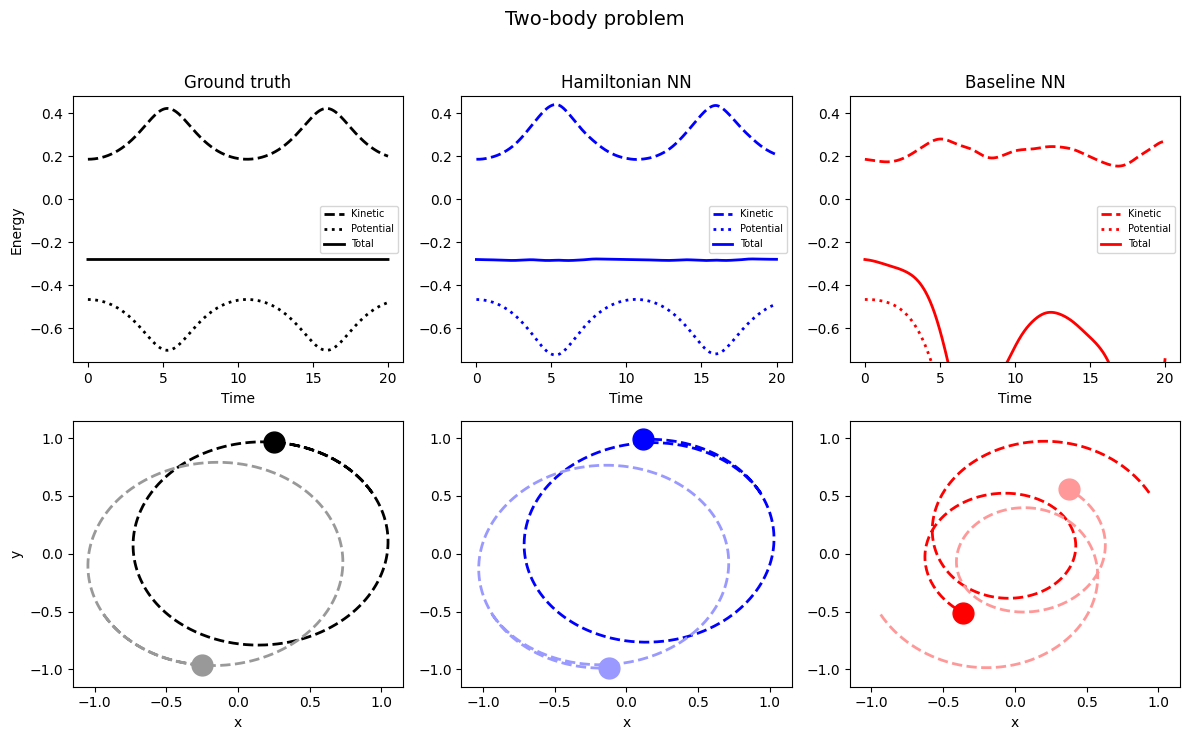

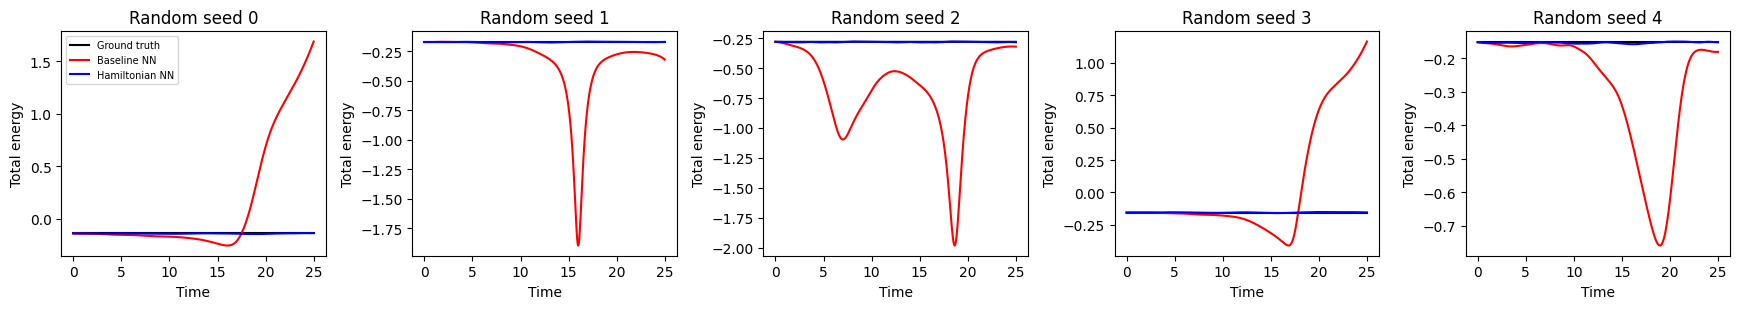

In [18]:
two_body_data = make_two_body_dataset()
two_body_nets = {kind: train_two_body(kind, two_body_data) for kind in FIELDS}
two_body_result = dict(data=two_body_data, nets=two_body_nets)
two_body_runs = two_body_energy_runs(two_body, two_body_nets)

report_two_body(two_body_result, two_body_runs)
plot_two_body(two_body, two_body_nets)
plot_two_body_energy_grid(two_body_runs)

save_nets(two_body_nets, 'two_body')
np.savez(os.path.join(RESULTS_DIR, 'two_body_energy_runs.npz'), **two_body_runs)   # energy curves behind the plots

## Summary

**What the experiments show.**

- **Frictionless systems (Sections 1 and 2).** The baseline and the HNN reach about the same single-step loss, so they fit the data about equally well. They differ in simulation: the baseline's energy drifts and its paths spiral, while the HNN conserves energy far better. On the spring the HNN's energy error was about two orders of magnitude below the baseline's in our runs, and on the pendulum it was clearly lower too.
- **Systems with friction (Section 3).** The advantage reverses. The HNN is restricted to constant-energy motion, so it cannot follow a path that loses energy, while the baseline can. The sweep over damping strength shows the crossover between the two regimes. The learned energy function of the HNN is still correct, but its dynamics are not.
- **A larger system (Section 4).** On the two-body problem, with an 8-dimensional state, the same helpers and the same HNN construction apply without modification. In the run we looked at, the HNN's training loss ended nearly an order of magnitude lower than the baseline's. The results table and the energy and trajectory plots at the end of Section 4 show how the two compare as simulators.

**Why the structure helps.** The HNN does not have to learn conservation from data. Any $H$ it learns produces motion that conserves $H$, so errors in the learned function change *which* quantity is conserved but never whether something is. That is why its energy stays bounded over long simulations.



## Save results

In [19]:
save_rows(ALL_ROWS, 'all_metrics')
shutil.make_archive('results', 'zip', RESULTS_DIR)
print('Saved:'); [print('  ', f) for f in sorted(os.listdir(RESULTS_DIR))]
try:
    from google.colab import files; files.download('results.zip')
except ImportError:
    print('results.zip is in the notebook folder')


Saved:
   Damped_mass_spring_0_1.png
   Damped_mass_spring_0_1_baseline.pt
   Damped_mass_spring_0_1_hnn.pt
   Damped_mass_spring_0_1_metrics.csv
   Damped_pendulum_0_1.png
   Damped_pendulum_0_1_baseline.pt
   Damped_pendulum_0_1_hnn.pt
   Damped_pendulum_0_1_metrics.csv
   Ideal_mass_spring.png
   Ideal_mass_spring_baseline.pt
   Ideal_mass_spring_hnn.pt
   Ideal_mass_spring_metrics.csv
   Ideal_pendulum.png
   Ideal_pendulum_baseline.pt
   Ideal_pendulum_hnn.pt
   Ideal_pendulum_metrics.csv
   all_metrics.csv
   gamma_sweep.csv
   gamma_sweep.json
   gamma_sweep.png
   two_body_baseline.pt
   two_body_energy_and_trajectories.png
   two_body_energy_grid.png
   two_body_energy_runs.npz
   two_body_hnn.pt
   two_body_metrics.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>